In [1]:
from quantify_core.data.handling import (
    default_datadir,
    get_latest_tuid,
    get_tuids_containing,
    load_dataset,
    locate_experiment_container,
    set_datadir,
)

import numpy as np
import matplotlib.pyplot as plt

from collections import OrderedDict

import deprecated
import matplotlib.pyplot as plt
import numpy as np
from pyDOE2 import lhs
import itertools
from numpy.typing import NDArray
import xarray as xr
from cmaes import CMA, get_warm_start_mgd
from typing import Tuple, Callable, List, Any, Optional, Dict
from qcodes import Parameter, validators
from quantify_core.measurement.control import MeasurementControl
from quantify_core.measurement.types import Settable, Gettable
from quantify_core.analysis.base_analysis import BaseAnalysis, BasicAnalysis
from quantify_core.visualization.mpl_plotting import set_suptitle_from_dataset
from quantify_core.data.handling import trim_dataset
from quantify_scheduler import Schedule
from quantify_scheduler.enums import BinMode

from quantify_core.analysis.base_analysis import Basic2DAnalysis
from quantify_core.data.handling import to_gridded_dataset, grow_dataset
from qce_utils.support_classes.utilities_array_shaping import (
    pairwise_complex,
    normalize_tensor_dataset,
    recursively_split_and_process_dataset,
)
from qce_utils.addon_quantify.decorator_metadata import metadata_from_function_signature
from qce_utils.addon_quantify.deserialize_xarray_to_obj import (
    DeserializeBootstrap,
    IXarrayBootstrap,
)

from qce_utils.qed_modeling.intrf_state_classification import (
    IQNDPiStateClassifierContainer,
)
from qce_utils.addon_quantify.object_factories.factory_state_acquisition import (
    QNDPiStateClassifierFactory,
    QNDPiStateClassifierContainer,
    QNDPiLandscapeFactory,
    MultiQubitQNDPiStateClassifierFactory,
    MultiQubitQNDPiStateClassifierContainer,
    AcquisitionType,
    MultiQubitQNDPiOptimizationFactory,
    StateKey,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_state_classification import (
    StateAxesProjectionAnalysis,
    QNDPiStateClassifierAnalysis,
    QNDPiLandscapeContainer,
    QNDPiLandscapeAnalysis,
    QNDPiAndSNRLandscapeAnalysis,
    LandscapeType,
    FigureContainer,
    QNDPiOptimizationAnalysis,
    MultiQubitReadoutOptimizationContainer,
    IReadoutOptimizationContainer,
    OptimizedReadoutParameters,
)
from qce_interp.interface_definitions.intrf_state_classification import (
    StateBoundaryKey,
    StateKey,
)
from qce_utils.addon_quantify.object_factories.factory_readout_transient import (
    OptimalWeightsFactory,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_readout_transient import (
    OptimalWeightsIdentifier,
    ReadoutTransientAnalysis,
    OptimalWeightsAnalysis as OptimalWeightsAnalysis_,
)
# from hqt_utils.operations.gate_library import Identity

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import colorsys

In [2]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [3]:
def process_CMAES_data(dataset, population_size, qubit_names=None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An object containing data attributes (e.g., dataset.x0.data, dataset.y0.data, etc.).
        population_size: The size of the population.
        nr_qubits: The number of qubits.

    Returns:
        A dictionary containing mean and population fidelity data for all qubit_names and shared parameters.
    """

    if qubit_names is None:
        if hasattr(dataset, "elements"):
            qubit_names = dataset.elements
        else:
            raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

    # Extract parameters shared across all qubits
    shared_data = {
        'objective': dataset.y0.data,
    }

    # Initialize dictionary to hold data for each qubit
    fidelity_data = {'shared': shared_data}

    name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
    name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}
        
    for qubit in qubit_names:
        # Extract fidelity data for the current qubit
        fidelity_data[qubit] = {
            'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
            'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
            'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
            'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
            'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
            'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
            'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
            'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
        }

        # Extract data of the mean
        fidelity_data[qubit]['mean'] = {
            key: fidelity_data[qubit][key][population_size::population_size + 1]
            for key in
            ['freq', 'ampl', 'dur', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        # Extract data of the population
        fidelity_data[qubit]['pop'] = {
            key: np.array([
                fidelity_data[qubit][key][i::population_size + 1]
                for i in range(population_size)
            ])
            for key in
            ['freq', 'ampl', 'dur', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndpifid']
        }

    return fidelity_data

In [8]:
Ngen = 150
popsize = 20

tuid = "20250909-000156-241-fbff28"
dataset_wo_alr = load_dataset(tuid=tuid)

tuid = "20250909-004947-529-181160"
dataset_alr = load_dataset(tuid=tuid)

data_wo_alr = process_CMAES_data(dataset_wo_alr,popsize)
data_alr = process_CMAES_data(dataset_alr, popsize)

In [9]:
#Compute mean and std of the last 10 generations
nr_gen = 10

fidelity = "qndpifid"

mean_wo = []
std_wo = []

mean_w = []
std_w = []

qubit_names = dataset_alr.elements
for qubit in qubit_names:
    mean_fidelity_wo_alr = np.mean(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    mean_wo.append(mean_fidelity_wo_alr)
    std_fidelity_wo_alr = np.std(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    std_wo.append(std_fidelity_wo_alr)

    mean_fidelity_alr = np.mean(data_alr[qubit]['mean'][fidelity][-nr_gen:])
    mean_w.append(mean_fidelity_alr)
    std_fidelity_alr = np.std(data_alr[qubit]['mean'][fidelity][-nr_gen:])
    std_w.append(std_fidelity_alr)

    print(f"Without adaptive lr: {qubit}: {mean_fidelity_wo_alr:.3f} +- {std_fidelity_wo_alr:.3f}")
    print(f"With adaptive lr: {qubit}: {mean_fidelity_alr:.3f} +- {std_fidelity_alr:.3f} \n")

print(f"Mean without adaptive lr mean: {np.mean(np.array(mean_wo)):.3f} +- {np.std(np.array(mean_wo)):.3f}")
print(f"Std without adaptive lr mean: {np.mean(np.array(std_wo)):.3f} +- {np.std(np.array(std_wo)):.3f}")
print(f"Mean with adaptive lr mean: {np.mean(np.array(mean_w)):.3f} +- {np.std(np.array(mean_w)):.3f}")
print(f"Std with adaptive lr mean: {np.mean(np.array(std_w)):.3f} +- {np.std(np.array(std_w)):.3f}")



Without adaptive lr: Z3: 0.955 +- 0.011
With adaptive lr: Z3: 0.970 +- 0.007 

Without adaptive lr: D7: 0.963 +- 0.010
With adaptive lr: D7: 0.956 +- 0.005 

Without adaptive lr: D4: 0.960 +- 0.009
With adaptive lr: D4: 0.959 +- 0.012 

Mean without adaptive lr mean: 0.960 +- 0.003
Std without adaptive lr mean: 0.010 +- 0.001
Mean with adaptive lr mean: 0.962 +- 0.006
Std with adaptive lr mean: 0.008 +- 0.003


In [11]:
#Compute mean and std of the last 10 generations
nr_gen = 10
popsize = 60
# max_gen = 125
# qubit_names=['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'X1', 'X2', 'X3', 'X4', 'Z1', 'Z2', 'Z3', 'Z4']

fidelity = "assignfid_av"

mean_wo = []
std_wo = []


tuid = "20250914-110500-690-99f7dd"
dataset_wo_alr = load_dataset(tuid=tuid)
data_wo_alr = process_CMAES_data(dataset_wo_alr,popsize)

qubit_names = np.sort(dataset_wo_alr.elements)

print(f"\033[1m{fidelity}:")

for qubit in qubit_names:
    mean_fidelity_wo_alr = np.mean(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    mean_wo.append(mean_fidelity_wo_alr)
    std_fidelity_wo_alr = np.std(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    std_wo.append(std_fidelity_wo_alr)


    print(f"\033[0m{qubit}: {mean_fidelity_wo_alr:.3f} +- {std_fidelity_wo_alr:.3f}")

print(f"Mean: {np.mean(np.array(mean_wo)):.3f} +- {np.std(np.array(mean_wo)):.3f}")
print(f"Std: {np.mean(np.array(std_wo)):.3f} +- {np.std(np.array(std_wo)):.3f}")

assignfid_av:
D1: 0.969 +- 0.004
D2: 0.891 +- 0.006
D3: 0.902 +- 0.009
D4: 0.929 +- 0.025
D5: 0.957 +- 0.005
D6: 0.913 +- 0.007
D7: 0.900 +- 0.002
D8: 0.985 +- 0.004
D9: 0.885 +- 0.007
X1: 0.812 +- 0.007
X2: 0.872 +- 0.014
X3: 0.868 +- 0.006
X4: 0.741 +- 0.010
Z1: 0.876 +- 0.006
Z2: 0.912 +- 0.005
Z3: 0.882 +- 0.007
Z4: 0.916 +- 0.005
Mean: 0.895 +- 0.055
Std: 0.007 +- 0.005


In [12]:
#Compute mean and std of the last 10 generations
nr_gen = 10

fidelity = "assignfid_01"

mean_wo = []
std_wo = []

print(f"\033[1m{fidelity}:")

for qubit in qubit_names:
    mean_fidelity_wo_alr = np.mean(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    mean_wo.append(mean_fidelity_wo_alr)
    std_fidelity_wo_alr = np.std(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    std_wo.append(std_fidelity_wo_alr)


    print(f"\033[0m{qubit}: {mean_fidelity_wo_alr:.3f} +- {std_fidelity_wo_alr:.3f}")

print(f"Mean: {np.mean(np.array(mean_wo)):.3f} +- {np.std(np.array(mean_wo)):.3f}")
print(f"Std: {np.mean(np.array(std_wo)):.3f} +- {np.std(np.array(std_wo)):.3f}")

assignfid_01:
D1: 0.994 +- 0.002
D2: 0.975 +- 0.006
D3: 0.983 +- 0.007
D4: 0.986 +- 0.004
D5: 0.970 +- 0.005
D6: 0.981 +- 0.005
D7: 0.976 +- 0.005
D8: 0.990 +- 0.003
D9: 0.943 +- 0.007
X1: 0.882 +- 0.009
X2: 0.963 +- 0.011
X3: 0.956 +- 0.008
X4: 0.811 +- 0.013
Z1: 0.963 +- 0.006
Z2: 0.903 +- 0.010
Z3: 0.964 +- 0.005
Z4: 0.934 +- 0.008
Mean: 0.951 +- 0.046
Std: 0.007 +- 0.003


In [13]:
#Compute mean and std of the last 10 generations
nr_gen = 10

fidelity = "qndpifid"

mean_wo = []
std_wo = []

print(f"\033[1m{fidelity}:")

for qubit in qubit_names:
    mean_fidelity_wo_alr = np.mean(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    mean_wo.append(mean_fidelity_wo_alr)
    std_fidelity_wo_alr = np.std(data_wo_alr[qubit]['mean'][fidelity][-nr_gen:])
    std_wo.append(std_fidelity_wo_alr)


    print(f"\033[0m{qubit}: {mean_fidelity_wo_alr:.3f} +- {std_fidelity_wo_alr:.3f}")

print(f"Mean: {np.mean(np.array(mean_wo)):.3f} +- {np.std(np.array(mean_wo)):.3f}")
print(f"Std: {np.mean(np.array(std_wo)):.3f} +- {np.std(np.array(std_wo)):.3f}")

qndpifid:
D1: 0.957 +- 0.017
D2: 0.903 +- 0.028
D3: 0.914 +- 0.031
D4: 0.760 +- 0.143
D5: 0.930 +- 0.013
D6: 0.916 +- 0.037
D7: 0.916 +- 0.011
D8: 0.967 +- 0.007
D9: 0.882 +- 0.012
X1: 0.767 +- 0.033
X2: 0.872 +- 0.050
X3: 0.853 +- 0.024
X4: 0.672 +- 0.021
Z1: 0.917 +- 0.014
Z2: 0.631 +- 0.037
Z3: 0.901 +- 0.024
Z4: 0.859 +- 0.018
Mean: 0.860 +- 0.093
Std: 0.031 +- 0.030


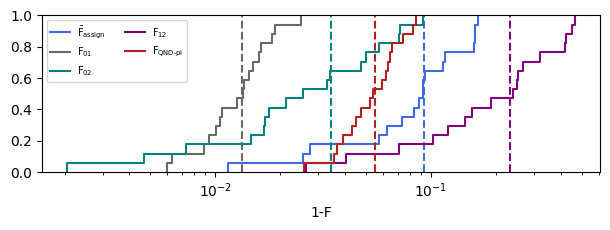

In [56]:
#Compute mean and std of the last 10 generations
nr_gen = 10
popsize = 60

tuid = "20250911-163302-486-9dc2e5"
dataset = load_dataset(tuid=tuid)
data = process_CMAES_data(dataset,popsize)

fidelities = ["assignfid_av", "assignfid_01", "assignfid_02", "assignfid_12", "qndpifid"]

qubit_names = np.sort(dataset.elements)

fidelity_dict = {}

for fidelity in fidelities:
    tmp_mean = []
    for qubit in qubit_names:
        mean_fidelity_wo_alr = np.mean(data[qubit]['mean'][fidelity][-nr_gen:])
        tmp_mean.append(mean_fidelity_wo_alr)

    fidelity_dict[fidelity] = tmp_mean
    
fig, ax = plt.subplots(ncols=1, nrows = 1)
fig.set_size_inches(6.2, 2.4)

ax.ecdf(1-np.array(fidelity_dict[fidelities[0]]), color="royalblue", label = r"$\bar{\text{F}}_{\text{assign}}$")
ax.vlines(np.mean(1-np.array(fidelity_dict[fidelities[0]])),0,1, ls = "--", color="royalblue")

ax.ecdf(1-np.array(fidelity_dict[fidelities[1]]), color="dimgrey", label = r"F$_{\text{01}}$")
ax.vlines(np.mean(1-np.array(fidelity_dict[fidelities[1]])),0,1, ls = "--", color="dimgrey" )

ax.ecdf(1-np.array(fidelity_dict[fidelities[2]]), color="teal", label = r"F$_{\text{02}}$")
ax.vlines(np.mean(1-np.array(fidelity_dict[fidelities[2]])),0,1, ls = "--", color="teal" )

ax.ecdf(1-np.array(fidelity_dict[fidelities[3]]), color="purple", label = r"F$_{\text{12}}$")
ax.vlines(np.mean(1-np.array(fidelity_dict[fidelities[3]])),0,1, ls = "--", color="purple" )

ax.ecdf(1-np.array(fidelity_dict[fidelities[4]]), color="firebrick", label = r"F$_{\text{QND-\pi}}$")
ax.vlines(np.mean(1-np.array(fidelity_dict[fidelities[4]])),0,1, ls = "--", color="firebrick")

ax.set_xlabel(r"1-F")
ax.legend(fontsize="x-small",ncols=2)
ax.set_xscale('log')

plt.tight_layout()
plt.show()

